# 02 · Small changes, big swings: tuning and parameter sweeps

Each strategy bot is one heuristic with ~15 parameters. *Identity* parameters (above all the per-resource weights that define the strategy) stay fixed; the rest are tuned by coordinate ascent against a field of the other four strategies, with common random numbers so every variant sees identical boards and dice.

Data: `results/tuning.json` (`python -m catanbot.sweep tune`) and `results/sweeps.json` (`python -m catanbot.pipeline sweeps`).

In [1]:
import json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"balanced": "#2a6f97", "ows": "#7d5ba6", "road_builder": "#b5532f", "dev_rush": "#3c8d5a",
          "port_master": "#c9962b", "greedy": "#8a8f98", "random": "#b8bcc4", "learned": "#d1495b"}
LABELS = {"balanced": "Balanced", "ows": "Ore-Wheat-Sheep", "road_builder": "Road Builder",
          "dev_rush": "Dev-Card Rush", "port_master": "Port Master", "learned": "Learned (RL)"}

tuning = json.loads((RESULTS / 'tuning.json').read_text())
sweeps = json.loads((RESULTS / 'sweeps.json').read_text())
print(f"tuning evaluated {len(tuning['log'])} variants x ~{tuning['log'][0]['games']:,} games each")

tuning evaluated 460 variants x ~16,000 games each


## Before and after tuning

In [2]:
rows = [{'strategy': LABELS[r['name']], 'hand-written': r['start_win_rate'], 'tuned': r['win_rate'],
         'gain (pts)': 100 * (r['win_rate'] - r['start_win_rate'])} for r in tuning['results']]
pl.DataFrame(rows)

strategy,hand-written,tuned,gain (pts)
str,f64,f64,f64
"""Balanced""",0.4609375,0.5339375,7.3
"""Ore-Wheat-Sheep""",0.217375,0.377125,15.975
"""Road Builder""",0.2336875,0.3383125,10.4625
"""Dev-Card Rush""",0.073125,0.2676875,19.45625
"""Port Master""",0.2615,0.27475,1.325


## Every accepted change
The trajectory of each strategy through coordinate ascent: which single-parameter changes beat the incumbent by more than 0.4 points.

In [3]:
log = pl.DataFrame(tuning['log'])
accepted = log.filter(pl.col('win_rate') > pl.col('baseline') + 0.004)
accepted.select(['preset', 'round', 'param', 'from', 'value', 'baseline', 'win_rate'])

preset,round,param,from,value,baseline,win_rate
str,i64,str,f64,f64,f64,f64
"""balanced""",0,"""diversity_weight""",1.5,1.875,0.4609375,0.4668125
"""balanced""",0,"""port_generic_weight""",1.0,1.5,0.4668125,0.4729375
"""balanced""",0,"""port_specific_weight""",0.15,0.225,0.4729375,0.4795625
"""balanced""",0,"""priority_city""",1.0,0.6,0.4795625,0.5055625
"""balanced""",0,"""priority_city""",0.6,0.8,0.5055625,0.51125
…,…,…,…,…,…,…
"""dev_rush""",1,"""priority_city""",1.2,1.5,0.2420625,0.24775
"""dev_rush""",1,"""priority_settlement""",1.2,1.5,0.24775,0.2583125
"""dev_rush""",1,"""discard_avoidance""",0.8,1.0,0.2583125,0.2676875


## Sensitivity of each tuned strategy
One parameter varied, everything else at its tuned value. Flat curves are robust settings; steep ones are where a strategy lives or dies.

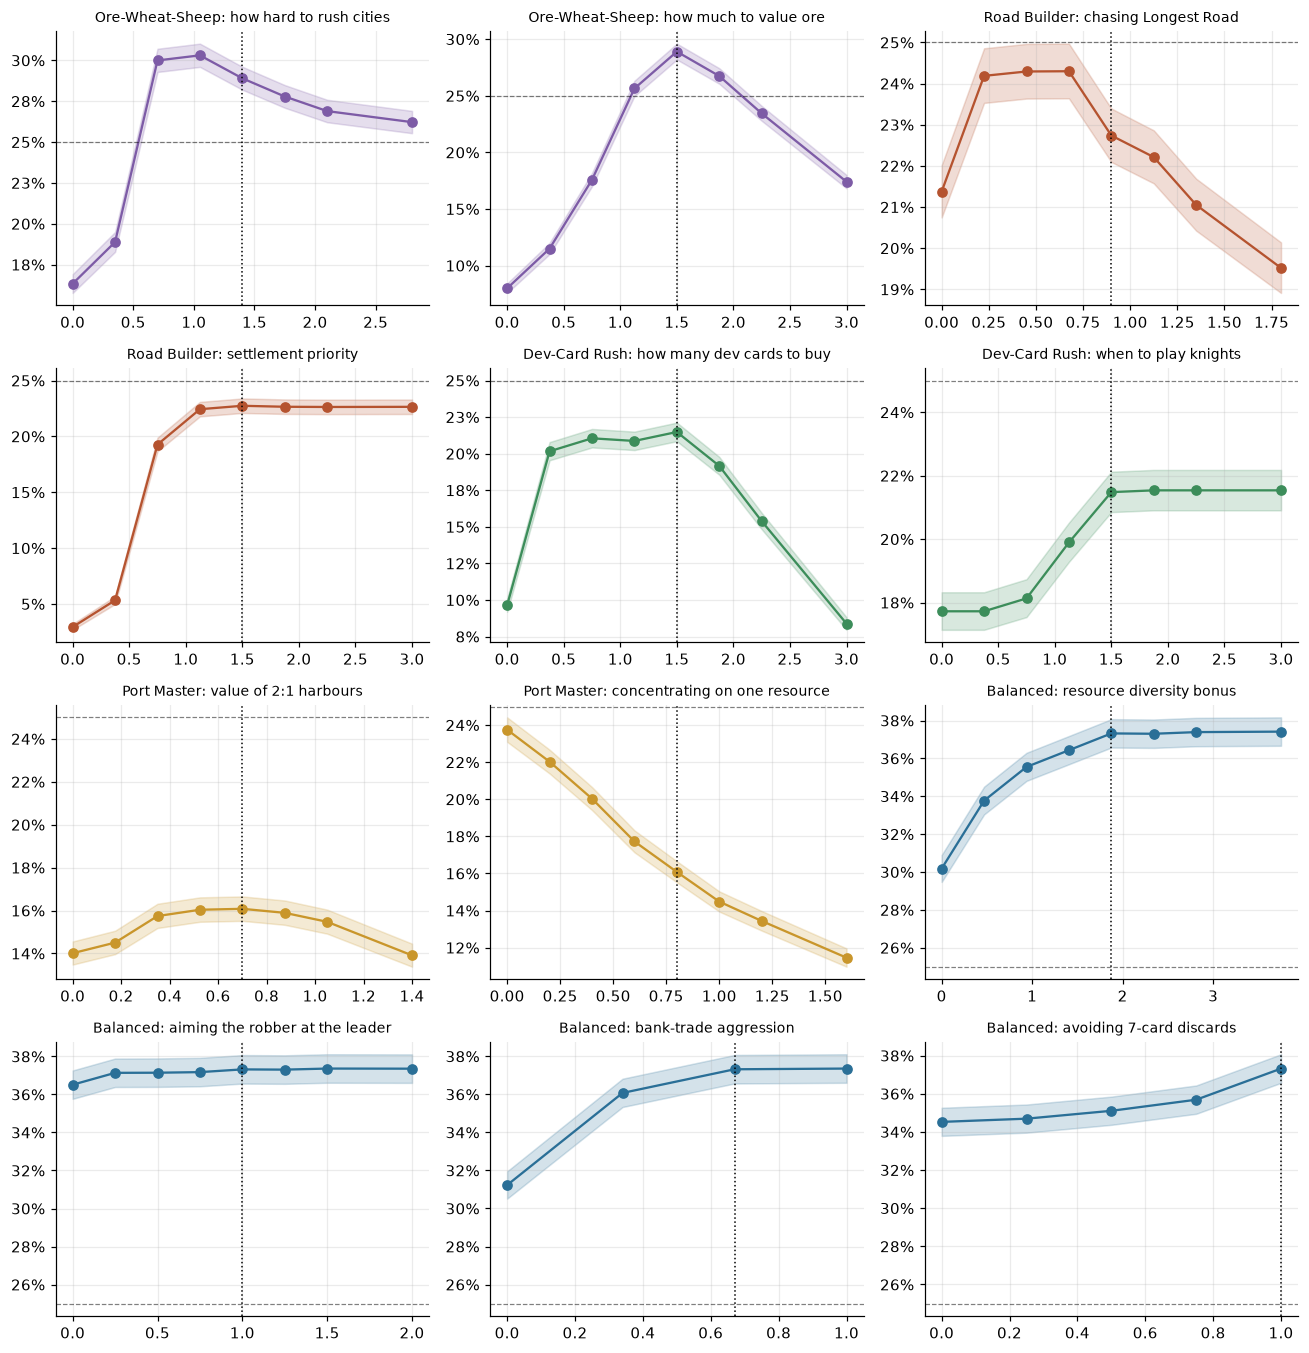

In [4]:
n = len(sweeps); cols = 3; rows_ = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_, cols, figsize=(12, 3.1 * rows_))
for ax, s in zip(axes.flat, sweeps):
    p = pl.DataFrame(s['points'])
    c = COLORS[s['preset']]
    ax.fill_between(p['value'], p['ci_low'], p['ci_high'], color=c, alpha=0.2)
    ax.plot(p['value'], p['win_rate'], 'o-', color=c)
    ax.axvline(s['default'], color='k', ls=':', lw=1)
    ax.axhline(0.25, color='k', ls='--', lw=0.8, alpha=0.5)
    ax.set_title(s['label'], fontsize=9); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for ax in list(axes.flat)[n:]: ax.axis('off')
plt.tight_layout(); plt.show()

## Takeaways
- The biggest gains came from **balance**: hand-written versions over-committed (Dev-Card Rush bought far too many cards; Ore-Wheat-Sheep refused to expand). Every strategy improved when it built more settlements.
- Bank-trade aggression and discard avoidance matter for every strategy. Dumping cards before a 7 is cheap insurance.
- The tuned bots are what the learning agent trains against, so they are deliberately made as strong as possible.